## 1. Importação das bibliotecas

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display, Markdown

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    KFold,
    GridSearchCV,
    cross_val_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC

SEMENTE = 42
plt.rcParams['figure.dpi'] = 110

print('Bibliotecas importadas com sucesso.')

Bibliotecas importadas com sucesso.


## 1.1 Leitura do dataset

In [2]:
# Primeiro, tento localizar o CSV no caminho usado no Kaggle.
CAMINHO_KAGGLE = Path(
    '/kaggle/input/datasets/harpartapsingh13/'
    'sleep-and-doomscrolling-habits-dataset/'
    'sleep_doomscrolling_habits.csv'
)

if CAMINHO_KAGGLE.exists():
    caminho = CAMINHO_KAGGLE
else:
    # Se o caminho padrão não existir, procuro o arquivo nas pastas de entrada.
    candidatos = list(Path('/kaggle/input').rglob('sleep_doomscrolling_habits.csv'))

    if candidatos:
        caminho = candidatos[0]
    else:
        # Última alternativa: baixar o dataset pelo KaggleHub.
        try:
            import kagglehub
            pasta = Path(kagglehub.dataset_download(
                'harpartapsingh13/sleep-and-doomscrolling-habits-dataset'
            ))
            candidatos = list(pasta.rglob('sleep_doomscrolling_habits.csv'))
            if not candidatos:
                raise FileNotFoundError('O CSV não foi encontrado na pasta baixada.')
            caminho = candidatos[0]
        except Exception as erro:
            raise FileNotFoundError(
                'Não encontrei sleep_doomscrolling_habits.csv. '
                'Confira se o dataset está anexado ao notebook do Kaggle.'
            ) from erro

df = pd.read_csv(caminho)
df.columns = df.columns.astype(str).str.strip()

print('Arquivo utilizado:', caminho)
print('Dimensões da base:', df.shape)
display(df.head())

Arquivo utilizado: /kaggle/input/datasets/harpartapsingh13/sleep-and-doomscrolling-habits-dataset/sleep_doomscrolling_habits.csv
Dimensões da base: (1000, 30)


,respondent_id,age,bedtime_screen_time_minutes,total_daily_screen_time_hours,doomscroll_sessions_per_night,avg_doomscroll_session_minutes,sleep_hours_per_night,sleep_latency_minutes,number_of_night_wakeups,caffeine_intake_mg_per_day,...,occupation_status,country_region,primary_device_used_at_night,bedtime_routine_type,uses_night_mode,keeps_phone_in_bedroom,consumes_negative_news_content,uses_sleep_tracking_app,doomscroller,sleep_quality_category
0,D30000,22,13.0,1.85,2,5.4,8.1,19.0,2,155.0,...,Unemployed,Germany,Tablet,Meditation/Journaling,Yes,Yes,Yes,No,Yes,Good
1,D30001,18,90.0,3.61,3,29.6,7.0,31.0,3,82.0,...,Student,India,Smartphone,Meditation/Journaling,No,Yes,Yes,No,Yes,Poor
2,D30002,37,51.0,5.15,3,15.5,7.1,24.0,2,49.0,...,Student,India,Laptop,Reading,No,Yes,No,Yes,Yes,Fair
3,D30003,27,53.0,3.74,0,51.4,8.4,35.0,0,42.0,...,NaN,United States,Smartphone,No Fixed Routine,No,Yes,Yes,No,No,Fair
4,D30004,17,67.0,6.09,2,32.2,7.2,19.0,1,76.0,...,Employed Part-time,United States,Smartphone,Watching Videos,No,No,No,No,No,Fair


## 2. Avaliação inicial do banco de dados

Antes de treinar qualquer modelo, é necessário entender o tamanho da base, os tipos de dados, os valores ausentes, as duplicatas e a distribuição do alvo. Nesta etapa, **apenas identificamos os ausentes; ainda não calculamos medianas ou modas para preenchê-los**.

In [3]:
print('Quantidade de linhas:', df.shape[0])
print('Quantidade de colunas:', df.shape[1])
print('\nTipos e quantidade de valores não ausentes:')
df.info()

Quantidade de linhas: 1000
Quantidade de colunas: 30

Tipos e quantidade de valores não ausentes:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 30 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   respondent_id                   1000 non-null   object 
 1   age                             1000 non-null   int64  
 2   bedtime_screen_time_minutes     1000 non-null   float64
 3   total_daily_screen_time_hours   1000 non-null   float64
 4   doomscroll_sessions_per_night   1000 non-null   int64  
 5   avg_doomscroll_session_minutes  1000 non-null   float64
 6   sleep_hours_per_night           1000 non-null   float64
 7   sleep_latency_minutes           1000 non-null   float64
 8   number_of_night_wakeups         1000 non-null   int64  
 9   caffeine_intake_mg_per_day      950 non-null    float64
 10  anxiety_score                   1000 non-null   int64  
 11

In [4]:
print('Valores ausentes por coluna:')
ausentes = df.isna().sum()
display(ausentes[ausentes > 0].to_frame('Quantidade de ausentes'))

print('Linhas totalmente duplicadas:', int(df.duplicated().sum()))

COLUNA_ALVO = 'sleep_quality_category'
if COLUNA_ALVO not in df.columns:
    raise KeyError(f'A coluna-alvo {COLUNA_ALVO!r} não existe na base.')

contagem = df[COLUNA_ALVO].value_counts().reindex(['Good', 'Fair', 'Poor'])
print('\nDistribuição do alvo em três categorias:')
display(contagem.to_frame('Registros'))

quantidade_poor = int((df[COLUNA_ALVO] == 'Poor').sum())
quantidade_nao_poor = int((df[COLUNA_ALVO] != 'Poor').sum())
print(f'Poor: {quantidade_poor} ({quantidade_poor / len(df) * 100:.1f}%)')
print(f'Não-Poor: {quantidade_nao_poor} ({quantidade_nao_poor / len(df) * 100:.1f}%)')

if df[COLUNA_ALVO].isna().any():
    raise ValueError('Há valores ausentes na variável-alvo. Eles precisam ser investigados antes da modelagem.')

classes_esperadas = {'Good', 'Fair', 'Poor'}
if set(df[COLUNA_ALVO].unique()) != classes_esperadas:
    raise ValueError(f'Categorias inesperadas no alvo: {sorted(df[COLUNA_ALVO].unique())}')

Valores ausentes por coluna:


,Quantidade de ausentes
caffeine_intake_mg_per_day,50
sleep_quality_score,40
exercise_minutes_per_day,50
occupation_status,30
primary_device_used_at_night,30
bedtime_routine_type,20


Linhas totalmente duplicadas: 0

Distribuição do alvo em três categorias:


,Registros
sleep_quality_category,
Good,340
Fair,330
Poor,330


Poor: 330 (33.0%)
Não-Poor: 670 (67.0%)


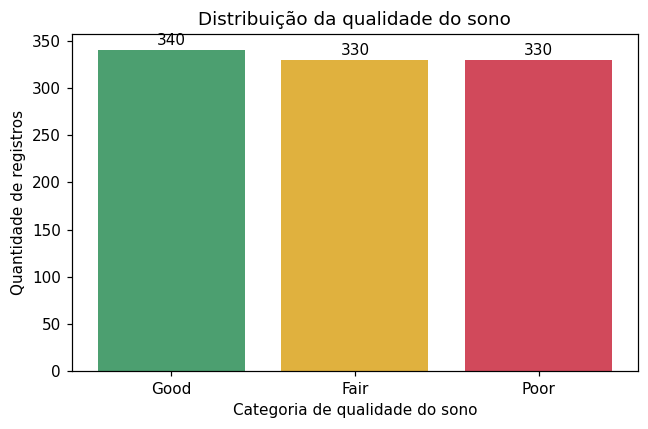

In [5]:
cores = {'Good': '#4C9F70', 'Fair': '#E0B13E', 'Poor': '#D1495B'}
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(contagem.index, contagem.values, color=[cores[c] for c in contagem.index])
for i, valor in enumerate(contagem.values):
    ax.text(i, valor + 5, str(valor), ha='center')
ax.set_title('Distribuição da qualidade do sono')
ax.set_xlabel('Categoria de qualidade do sono')
ax.set_ylabel('Quantidade de registros')
plt.tight_layout()
plt.show()

### Como interpretar esta etapa

No arquivo original, a variável `sleep_quality_category` tinha 340 registros `Good`, 330 `Fair` e 330 `Poor`. No alvo binário, isso corresponde a aproximadamente 67% de `não-Poor` e 33% de `Poor`.

A **linha de base** da classificação binária é a proporção da classe majoritária: um modelo que previsse sempre `não-Poor` teria aproximadamente 67% de acurácia. O SVM precisa ser comparado com essa referência.

Os dados ausentes devem ser tratados antes de o algoritmo receber os dados, mas as estatísticas usadas no preenchimento (mediana e moda) precisam ser calculadas somente com o treino de cada divisão. Essa distinção evita vazamento de dados.

## 3. Análise exploratória e criação de variáveis descritivas

As variáveis abaixo ajudam a descrever o dataset e comparar grupos. Os grupos de exposição são usados apenas nas análises descritivas; eles não serão usados como preditores do SVM.

In [6]:
# Estimativa do tempo de doomscrolling por noite:
# quantidade de sessões × duração média de cada sessão.
df['doomscroll_minutes_per_night'] = (
    df['doomscroll_sessions_per_night'] * df['avg_doomscroll_session_minutes']
)

# Variáveis combinadas para a análise descritiva.
df['screen_doom_total'] = (
    df['bedtime_screen_time_minutes'] + df['doomscroll_minutes_per_night']
)
df['screen_doom_interaction'] = (
    df['bedtime_screen_time_minutes'] * df['doomscroll_minutes_per_night']
)

# A mediana separa grupos de exposição baixa/alta para comparação.
# Não é um limite clínico.
mediana_tela = df['bedtime_screen_time_minutes'].median()
mediana_doom = df['doomscroll_minutes_per_night'].median()

df['screen_group'] = np.where(
    df['bedtime_screen_time_minutes'] > mediana_tela,
    'Maior uso de tela', 'Menor uso de tela'
)
df['doom_group'] = np.where(
    df['doomscroll_minutes_per_night'] > mediana_doom,
    'Maior doomscrolling', 'Menor doomscrolling'
)

alta_tela = df['bedtime_screen_time_minutes'] > mediana_tela
alto_doom = df['doomscroll_minutes_per_night'] > mediana_doom

df['exposure_group'] = np.select(
    [~alta_tela & ~alto_doom,
     alta_tela & ~alto_doom,
     ~alta_tela & alto_doom,
     alta_tela & alto_doom],
    ['Baixa tela + Baixo doom',
     'Alta tela + Baixo doom',
     'Baixa tela + Alto doom',
     'Alta tela + Alto doom'],
    default='Não classificado'
)

print('Mediana da tela antes de dormir:', round(mediana_tela, 2), 'minutos')
print('Mediana do doomscrolling estimado:', round(mediana_doom, 2), 'minutos')

Mediana da tela antes de dormir: 44.0 minutos
Mediana do doomscrolling estimado: 42.35 minutos


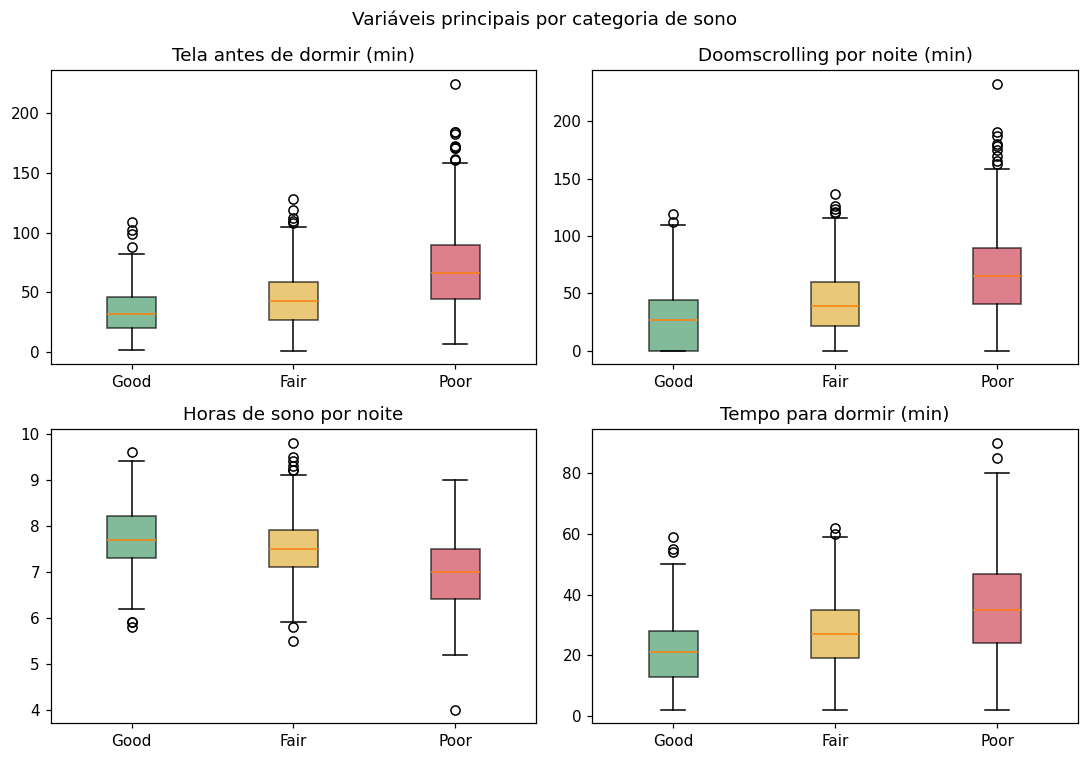

In [7]:
ordem_cat = ['Good', 'Fair', 'Poor']
variaveis = [
    ('bedtime_screen_time_minutes', 'Tela antes de dormir (min)'),
    ('doomscroll_minutes_per_night', 'Doomscrolling por noite (min)'),
    ('sleep_hours_per_night', 'Horas de sono por noite'),
    ('sleep_latency_minutes', 'Tempo para dormir (min)'),
]

fig, eixos = plt.subplots(2, 2, figsize=(10, 7))
for ax, (coluna, titulo) in zip(eixos.ravel(), variaveis):
    dados_por_categoria = [
        df.loc[df[COLUNA_ALVO] == categoria, coluna].dropna()
        for categoria in ordem_cat
    ]
    caixas = ax.boxplot(dados_por_categoria, patch_artist=True)
    for caixa, categoria in zip(caixas['boxes'], ordem_cat):
        caixa.set_facecolor(cores[categoria])
        caixa.set_alpha(0.7)
    ax.set_xticks([1, 2, 3])
    ax.set_xticklabels(ordem_cat)
    ax.set_title(titulo)

plt.suptitle('Variáveis principais por categoria de sono')
plt.tight_layout()
plt.show()

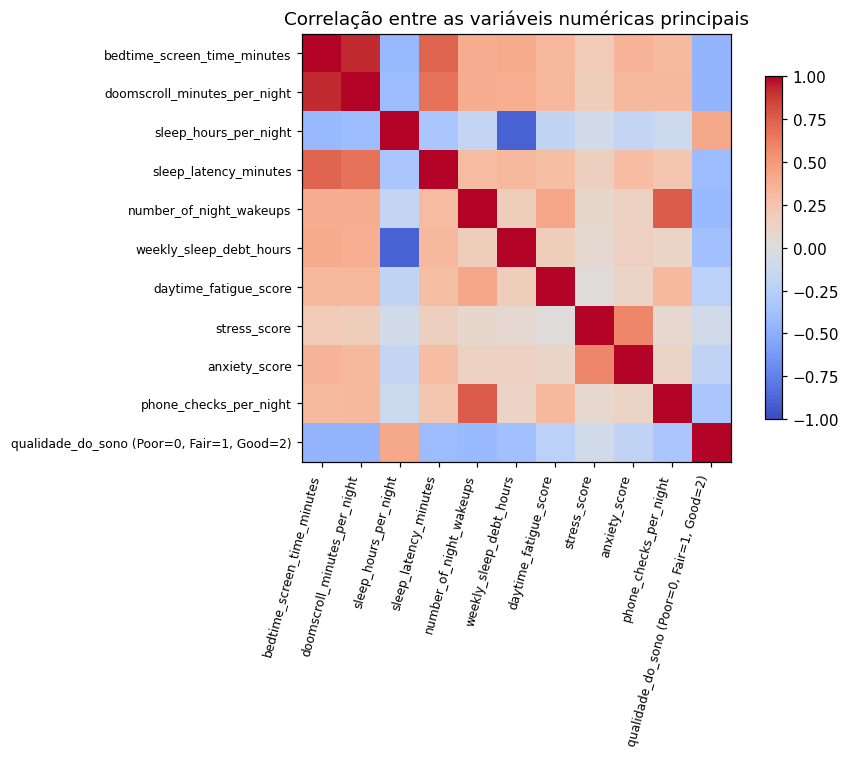

In [8]:
colunas_correlacao = [
    'bedtime_screen_time_minutes',
    'doomscroll_minutes_per_night',
    'sleep_hours_per_night',
    'sleep_latency_minutes',
    'number_of_night_wakeups',
    'weekly_sleep_debt_hours',
    'daytime_fatigue_score',
    'stress_score',
    'anxiety_score',
    'phone_checks_per_night',
]

base_correlacao = df[colunas_correlacao].copy()
base_correlacao['qualidade_do_sono (Poor=0, Fair=1, Good=2)'] = (
    df[COLUNA_ALVO].map({'Poor': 0, 'Fair': 1, 'Good': 2})
)
matriz_correlacao = base_correlacao.corr()

fig, ax = plt.subplots(figsize=(9, 7))
imagem = ax.imshow(matriz_correlacao, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(matriz_correlacao)))
ax.set_yticks(range(len(matriz_correlacao)))
ax.set_xticklabels(matriz_correlacao.columns, rotation=75, ha='right', fontsize=8)
ax.set_yticklabels(matriz_correlacao.columns, fontsize=8)
fig.colorbar(imagem, ax=ax, shrink=0.8)
ax.set_title('Correlação entre as variáveis numéricas principais')
plt.tight_layout()
plt.show()

### Leitura da análise exploratória

Os boxplots permitem comparar mediana, dispersão e sobreposição entre `Good`, `Fair` e `Poor`. A matriz de correlação mostra associações lineares entre variáveis numéricas; correlação não demonstra causalidade.

A criação de `doomscroll_minutes_per_night`, `screen_doom_total` e `screen_doom_interaction` é uma etapa de engenharia de atributos. Os grupos `screen_group`, `doom_group` e `exposure_group` são categorias descritivas, por isso serão excluídos de `X` para evitar que o modelo receba rótulos criados diretamente a partir dos próprios grupos de exposição.

## 4. Definição das variáveis de entrada (`X`) e da variável-alvo (`y`)

No aprendizado supervisionado, `X` contém as características usadas para fazer a previsão e `y` contém a resposta que o modelo deve aprender.

In [9]:
# Indicador binário: 1 significa que o escore original estava ausente.
# A informação de ausência é conhecida por registro e não exige calcular
# uma estatística usando a base inteira.
df['sleep_quality_score_ausente'] = (
    df['sleep_quality_score'].isna().astype(int)
)

# Mantemos a variável-alvo original em três categorias.
y = df[COLUNA_ALVO].copy()
y_bin = (y == 'Poor').astype(int)

# Removemos identificador, alvo e grupos descritivos.
# As variáveis numéricas e categóricas restantes serão tratadas no Pipeline.
colunas_excluir = {
    'respondent_id',
    COLUNA_ALVO,
    'screen_group',
    'doom_group',
    'exposure_group',
}
X = df.drop(columns=list(colunas_excluir)).copy()

# Valores infinitos passam a ser ausentes para que o imputador possa tratá-los.
X = X.replace([np.inf, -np.inf], np.nan)

print('Dimensões de X:', X.shape)
print('Dimensões de y:', y.shape)
print('Proporção da classe Poor:', round(y_bin.mean(), 3))
print('Valores ausentes ainda presentes em X:', int(X.isna().sum().sum()))
print('Colunas categóricas:', X.select_dtypes(exclude=np.number).columns.tolist())
print('Colunas numéricas:', X.select_dtypes(include=np.number).columns.tolist())

Dimensões de X: (1000, 32)
Dimensões de y: (1000,)
Proporção da classe Poor: 0.33
Valores ausentes ainda presentes em X: 220
Colunas categóricas: ['gender', 'occupation_status', 'country_region', 'primary_device_used_at_night', 'bedtime_routine_type', 'uses_night_mode', 'keeps_phone_in_bedroom', 'consumes_negative_news_content', 'uses_sleep_tracking_app', 'doomscroller']
Colunas numéricas: ['age', 'bedtime_screen_time_minutes', 'total_daily_screen_time_hours', 'doomscroll_sessions_per_night', 'avg_doomscroll_session_minutes', 'sleep_hours_per_night', 'sleep_latency_minutes', 'number_of_night_wakeups', 'caffeine_intake_mg_per_day', 'anxiety_score', 'stress_score', 'sleep_quality_score', 'daytime_fatigue_score', 'number_of_news_apps_used', 'phone_checks_per_night', 'exercise_minutes_per_day', 'days_since_last_digital_detox', 'weekly_sleep_debt_hours', 'doomscroll_minutes_per_night', 'screen_doom_total', 'screen_doom_interaction', 'sleep_quality_score_ausente']


### Atenção à interpretação das variáveis

`respondent_id` é um identificador, não uma característica explicativa; por isso foi removido. A variável `sleep_quality_category` é o alvo e nunca pode permanecer em `X`.

**`sleep_quality_score` foi mantida em `X`**, conforme a definição adotada no trabalho e a orientação que você recebeu. Porém, é importante conferir na descrição do dataset como esse escore foi construído. Se ele for calculado diretamente a partir de `sleep_quality_category`, poderá haver vazamento do alvo. Não o removi sem essa confirmação, mas o modelo deve ser interpretado como uma classificação que utiliza também um escore relacionado ao sono — não como previsão baseada somente em telas e doomscrolling.

Também permanecem em `X` outras medidas de sono e bem-estar já usadas no notebook original. Portanto, a pergunta sobre telas e doomscrolling é respondida principalmente pelas análises de associação; o SVM é um classificador multivariado com as características disponíveis.

## 5. Separação entre treino e teste

In [10]:
# Dividimos antes de calcular medianas, modas ou categorias do One-Hot Encoding.
# A estratificação usa as três categorias para manter proporções semelhantes.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEMENTE,
    stratify=y,
)

y_train_bin = (y_train == 'Poor').astype(int)
y_test_bin = (y_test == 'Poor').astype(int)

y_train_good = (y_train == 'Good').astype(int)
y_test_good = (y_test == 'Good').astype(int)

print('Treino:', X_train.shape)
print('Teste:', X_test.shape)
print('Proporção Poor no treino:', round(y_train_bin.mean(), 3))
print('Proporção Poor no teste:', round(y_test_bin.mean(), 3))

Treino: (800, 32)
Teste: (200, 32)
Proporção Poor no treino: 0.33
Proporção Poor no teste: 0.33


### Por que dividir antes do tratamento?

O conjunto de treino serve para o modelo aprender e para ajustar o pré-processamento. O conjunto de teste fica separado para estimar o desempenho final.

Se a mediana fosse calculada antes da divisão, por exemplo, o valor seria influenciado também pelos registros de teste. O mesmo princípio vale para a moda e para a lista de categorias usadas no One-Hot Encoding. Por isso, essas operações serão aprendidas dentro do pipeline durante cada fold da validação cruzada.

## 6. Tratamento dos dados e padronização com `ColumnTransformer` e `Pipeline`

In [11]:
# Identificamos os tipos de coluna usando apenas X_train.
colunas_numericas = X_train.select_dtypes(include=np.number).columns.tolist()
colunas_categoricas = X_train.select_dtypes(exclude=np.number).columns.tolist()

# Etapas para variáveis numéricas:
# 1) preencher ausentes pela mediana calculada no treino;
# 2) padronizar para média próxima de 0 e desvio padrão próximo de 1.
preparo_numerico = Pipeline(steps=[
    ('imputacao', SimpleImputer(strategy='median')),
    ('padronizacao', StandardScaler()),
])

# Compatibilidade com versões diferentes do scikit-learn.
try:
    codificador = OneHotEncoder(
        drop='first', handle_unknown='ignore', sparse_output=False
    )
except TypeError:
    codificador = OneHotEncoder(
        drop='first', handle_unknown='ignore', sparse=False
    )

# Etapas para variáveis categóricas:
# 1) preencher ausentes pela categoria mais frequente no treino;
# 2) converter categorias em colunas numéricas (One-Hot Encoding).
preparo_categorico = Pipeline(steps=[
    ('imputacao', SimpleImputer(strategy='most_frequent')),
    ('one_hot', codificador),
])

# O ColumnTransformer aplica cada sequência ao tipo correto de coluna.
preprocessador = ColumnTransformer(
    transformers=[
        ('numericas', preparo_numerico, colunas_numericas),
        ('categoricas', preparo_categorico, colunas_categoricas),
    ],
    remainder='drop',
    sparse_threshold=0.0,
)

print('Variáveis numéricas:', len(colunas_numericas))
print('Variáveis categóricas:', len(colunas_categoricas))
print('Pipeline de pré-processamento definido.')

Variáveis numéricas: 22
Variáveis categóricas: 10
Pipeline de pré-processamento definido.


### O que acontece dentro do pipeline?

- **`SimpleImputer(strategy='median')`:** substitui cada valor numérico ausente pela mediana calculada somente com a parte de treino do fold atual. A mediana é menos sensível a valores extremos do que a média.
- **`StandardScaler`:** transforma as variáveis numéricas para escalas comparáveis. Isso é importante porque o SVM depende de distâncias e margens.
- **`SimpleImputer(strategy='most_frequent')`:** preenche categorias ausentes com a categoria mais frequente no treino.
- **`OneHotEncoder`:** transforma categorias, como tipo de dispositivo ou ocupação, em colunas numéricas. `handle_unknown='ignore'` evita erro caso apareça no teste uma categoria que não apareceu no treino.
- **`ColumnTransformer`:** envia cada grupo de colunas para o tratamento adequado.
- **`Pipeline`:** garante que o tratamento seja ajustado de novo dentro de cada fold, evitando que a validação veja estatísticas do fold que está sendo avaliado.

O `drop='first'` remove uma categoria de referência em cada variável categórica, evitando uma coluna redundante em determinadas codificações.

## 7. Treinamento do SVM inicial

In [12]:
# O SVM inicial funciona como referência antes do GridSearchCV.
# A avaliação é feita por validação cruzada SOMENTE no conjunto de treino.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)

svm_inicial = Pipeline(steps=[
    ('preprocessamento', clone(preprocessador)),
    ('svm', SVC(kernel='rbf', C=1, gamma='scale')),
])

acuracias_iniciais = cross_val_score(
    svm_inicial,
    X_train,
    y_train_bin,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1,
)

print('Acurácias nos 5 folds:', np.round(acuracias_iniciais, 4))
print(f'Média da acurácia: {acuracias_iniciais.mean():.4f}')
print(f'Desvio padrão: {acuracias_iniciais.std():.4f}')

Acurácias nos 5 folds: [0.7375 0.8188 0.8438 0.7812 0.7812]
Média da acurácia: 0.7925
Desvio padrão: 0.0363


### Como funciona a validação cruzada estratificada?

Em `StratifiedKFold(n_splits=5)`, o treino é dividido em cinco partes mantendo aproximadamente a proporção entre `Poor` e `não-Poor` em cada parte. Em cada rodada, quatro partes treinam o pipeline e a parte restante valida o resultado. O processo se repete até que cada parte tenha sido usada como validação.

A média resume o desempenho entre as divisões; o desvio padrão mostra quanto o resultado varia de um fold para outro. Nesta etapa, ainda não usamos o conjunto de teste.

## 8. Otimização do SVM com `GridSearchCV`

In [13]:
# Versão base: testa kernels e valores de C sem seleção de variáveis.
pipe_base = Pipeline(steps=[
    ('preprocessamento', clone(preprocessador)),
    ('svm', SVC()),
])

grade_base = [
    {
        'svm__kernel': ['linear'],
        'svm__C': [0.01, 0.1, 1, 10],
    },
    {
        'svm__kernel': ['rbf'],
        'svm__C': [0.1, 1, 10, 100],
        'svm__gamma': ['scale', 0.001, 0.01, 0.1],
    },
]

gs_base = GridSearchCV(
    estimator=pipe_base,
    param_grid=grade_base,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1,
    refit=True,
)
gs_base.fit(X_train, y_train_bin)

print('SVM base — todas as variáveis')
print('Melhores parâmetros:', gs_base.best_params_)
print('Melhor acurácia média na validação:', round(gs_base.best_score_, 4))

# Versão com seleção de variáveis e possibilidade de ponderar as classes.
pipe_sel = Pipeline(steps=[
    ('preprocessamento', clone(preprocessador)),
    ('selecao', SelectKBest(score_func=f_classif)),
    ('svm', SVC()),
])

grade_sel = [
    {
        'selecao__k': [6, 10, 15, 'all'],
        'svm__kernel': ['linear'],
        'svm__C': [0.01, 0.1, 1, 10],
        'svm__class_weight': [None, 'balanced'],
    },
    {
        'selecao__k': [6, 10, 15, 'all'],
        'svm__kernel': ['rbf'],
        'svm__C': [0.1, 1, 10, 100],
        'svm__gamma': ['scale', 0.001, 0.01, 0.1],
        'svm__class_weight': [None, 'balanced'],
    },
]

gs_sel = GridSearchCV(
    estimator=pipe_sel,
    param_grid=grade_sel,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1,
    refit=True,
)
gs_sel.fit(X_train, y_train_bin)

print('\nSVM com seleção de variáveis')
print('Melhores parâmetros:', gs_sel.best_params_)
print('Melhor acurácia média na validação:', round(gs_sel.best_score_, 4))

SVM base — todas as variáveis
Melhores parâmetros: {'svm__C': 0.1, 'svm__kernel': 'linear'}
Melhor acurácia média na validação: 0.7975

SVM com seleção de variáveis
Melhores parâmetros: {'selecao__k': 15, 'svm__C': 0.1, 'svm__class_weight': None, 'svm__kernel': 'linear'}
Melhor acurácia média na validação: 0.8188


### O que o `GridSearchCV` está procurando?

- **`kernel`:** define a forma da fronteira de decisão. `linear` cria uma fronteira linear; `rbf` permite uma fronteira não linear.
- **`C`:** controla a penalização dos erros de treinamento. Valores maiores penalizam mais os erros; valores menores permitem mais erros em troca de uma margem potencialmente mais ampla.
- **`gamma`:** controla a influência de cada registro no kernel RBF. Valores maiores tendem a criar fronteiras mais locais e complexas; valores menores produzem influência mais ampla.
- **`SelectKBest`:** seleciona as `k` variáveis com maior pontuação segundo `f_classif`. Como está dentro do pipeline, a seleção é refeita dentro de cada fold.
- **`class_weight='balanced'`:** ajusta os pesos inversamente à frequência das classes no treino; pode ajudar quando uma classe aparece menos.

O `GridSearchCV` testa as combinações na validação cruzada do treino e escolhe a maior acurácia média. O teste não participa dessa escolha. A grade completa é computacionalmente mais pesada do que treinar um único SVM.

## 9. Escolha do modelo e avaliação no teste

In [14]:
# Escolhemos a busca com maior acurácia média de validação cruzada.
# Esta decisão é tomada sem consultar y_test.
if gs_sel.best_score_ > gs_base.best_score_:
    melhor_busca = gs_sel
    nome_final = 'SVM com seleção de variáveis'
else:
    melhor_busca = gs_base
    nome_final = 'SVM base'

# Com refit=True, o GridSearchCV já ajustou o melhor pipeline em todo X_train.
modelo_final = melhor_busca.best_estimator_

# Primeira avaliação do conjunto de teste para o desfecho binário principal.
y_pred_bin = modelo_final.predict(X_test)
acuracia_teste = accuracy_score(y_test_bin, y_pred_bin)

print('Modelo selecionado:', nome_final)
print('Parâmetros escolhidos:', melhor_busca.best_params_)
print('Acurácia média na validação cruzada:', round(melhor_busca.best_score_, 4))
print('Acurácia no teste:', round(acuracia_teste, 4))

Modelo selecionado: SVM com seleção de variáveis
Parâmetros escolhidos: {'selecao__k': 15, 'svm__C': 0.1, 'svm__class_weight': None, 'svm__kernel': 'linear'}
Acurácia média na validação cruzada: 0.8188
Acurácia no teste: 0.81


### Por que o teste fica no final?

Se usarmos o teste para escolher `C`, kernel, `gamma` ou quantidade de variáveis, o resultado deixa de ser uma avaliação independente: as decisões passam a se adaptar também aos erros daquele conjunto.

Por isso, o modelo é escolhido pela validação cruzada no treino. Só então o melhor pipeline faz previsões no teste. O `GridSearchCV` com `refit=True` reajusta o pipeline escolhido usando todo o conjunto de treino antes dessa avaliação.

## 10. Métricas do modelo binário

In [15]:
nomes_bin = ['Não-Poor', 'Poor']

linha_base = max(y_test_bin.mean(), 1 - y_test_bin.mean())
acc_bal = balanced_accuracy_score(y_test_bin, y_pred_bin)
prec_poor = precision_score(y_test_bin, y_pred_bin, zero_division=0)
rec_poor = recall_score(y_test_bin, y_pred_bin, zero_division=0)
f1_poor = f1_score(y_test_bin, y_pred_bin, zero_division=0)

pontuacao = modelo_final.decision_function(X_test)
auc_poor = roc_auc_score(y_test_bin, pontuacao)

# Intervalo normal aproximado para a acurácia (não é uma garantia de generalização).
erro_padrao = np.sqrt(acuracia_teste * (1 - acuracia_teste) / len(y_test_bin))
ic_inf = max(0, acuracia_teste - 1.96 * erro_padrao)
ic_sup = min(1, acuracia_teste + 1.96 * erro_padrao)

print(f'Acurácia no teste: {acuracia_teste * 100:.1f}%')
print(f'IC 95% aproximado: {ic_inf * 100:.1f}% a {ic_sup * 100:.1f}%')
print(f'Linha de base (classe majoritária): {linha_base * 100:.1f}%')
print(f'Ganho sobre a linha de base: {(acuracia_teste - linha_base) * 100:.1f} pontos percentuais')
print(f'Acurácia balanceada: {acc_bal * 100:.1f}%')
print(f'Poor — precisão: {prec_poor:.3f}')
print(f'Poor — recall/sensibilidade: {rec_poor:.3f}')
print(f'Poor — F1-score: {f1_poor:.3f}')
print(f'AUC: {auc_poor:.3f}')
print('\nRelatório de classificação:')
print(classification_report(
    y_test_bin,
    y_pred_bin,
    labels=[0, 1],
    target_names=nomes_bin,
    digits=3,
    zero_division=0,
))

Acurácia no teste: 81.0%
IC 95% aproximado: 75.6% a 86.4%
Linha de base (classe majoritária): 67.0%
Ganho sobre a linha de base: 14.0 pontos percentuais
Acurácia balanceada: 76.6%
Poor — precisão: 0.750
Poor — recall/sensibilidade: 0.636
Poor — F1-score: 0.689
AUC: 0.869

Relatório de classificação:
              precision    recall  f1-score   support

    Não-Poor      0.833     0.896     0.863       134
        Poor      0.750     0.636     0.689        66

    accuracy                          0.810       200
   macro avg      0.792     0.766     0.776       200
weighted avg      0.806     0.810     0.806       200



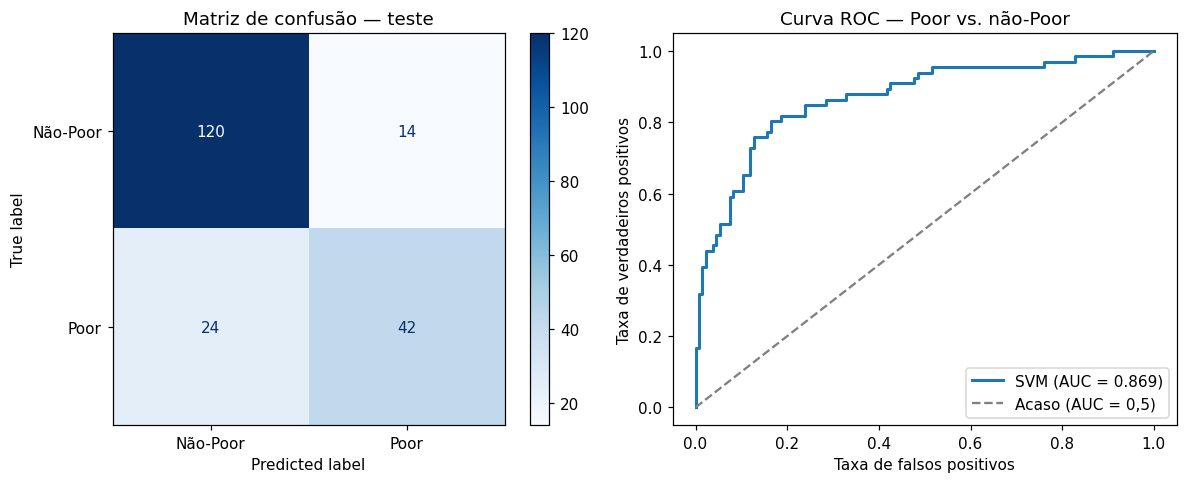

In [16]:
fig, eixos = plt.subplots(1, 2, figsize=(11, 4.5))

ConfusionMatrixDisplay.from_predictions(
    y_test_bin,
    y_pred_bin,
    labels=[0, 1],
    display_labels=nomes_bin,
    cmap='Blues',
    ax=eixos[0],
)
eixos[0].set_title('Matriz de confusão — teste')

fpr, tpr, _ = roc_curve(y_test_bin, pontuacao)
eixos[1].plot(fpr, tpr, lw=2, label=f'SVM (AUC = {auc_poor:.3f})')
eixos[1].plot([0, 1], [0, 1], '--', color='gray', label='Acaso (AUC = 0,5)')
eixos[1].set_xlabel('Taxa de falsos positivos')
eixos[1].set_ylabel('Taxa de verdadeiros positivos')
eixos[1].set_title('Curva ROC — Poor vs. não-Poor')
eixos[1].legend(loc='lower right')

plt.tight_layout()
plt.show()

### Como ler as métricas?

- **Acurácia:** proporção total de previsões corretas. Deve ser comparada com a linha de base.
- **Acurácia balanceada:** média do recall de cada classe; evita que a classe majoritária domine sozinha a avaliação.
- **Precisão de `Poor`:** entre os registros que o modelo chamou de `Poor`, quantos realmente eram `Poor`.
- **Recall/sensibilidade de `Poor`:** entre todos os registros realmente `Poor`, quantos o modelo encontrou.
- **F1-score:** média harmônica entre precisão e recall.
- **AUC:** capacidade de ordenar registros positivos acima dos negativos em diferentes limiares; 0,5 equivale ao acaso e 1,0 à separação perfeita.
- **Matriz de confusão:** mostra verdadeiros e falsos positivos/negativos.

Não interprete uma acurácia alta isoladamente: se o recall de `Poor` for baixo, o modelo pode deixar passar muitos casos de sono ruim.

## 11. Comparação exploratória com outros algoritmos (somente no treino)

In [17]:
# Comparação exploratória: todos os modelos são avaliados nas mesmas divisões
# de validação cruzada e somente dentro do conjunto de treino.
# Não usamos X/y completos nem consultamos o conjunto de teste nesta tabela.
modelos_comparacao = {
    'Regressão logística': Pipeline(steps=[
        ('preprocessamento', clone(preprocessador)),
        ('modelo', LogisticRegression(max_iter=2000)),
    ]),
    'SVM inicial': Pipeline(steps=[
        ('preprocessamento', clone(preprocessador)),
        ('modelo', SVC(kernel='rbf', C=1, gamma='scale')),
    ]),
    'Random Forest': Pipeline(steps=[
        ('preprocessamento', clone(preprocessador)),
        ('modelo', RandomForestClassifier(n_estimators=300, random_state=SEMENTE)),
    ]),
    'Gradient Boosting': Pipeline(steps=[
        ('preprocessamento', clone(preprocessador)),
        ('modelo', HistGradientBoostingClassifier(random_state=SEMENTE)),
    ]),
}

linhas_comparacao = []
for nome, modelo in modelos_comparacao.items():
    acc = cross_val_score(
        modelo, X_train, y_train_bin, cv=cv,
        scoring='accuracy', n_jobs=-1
    )
    auc = cross_val_score(
        modelo, X_train, y_train_bin, cv=cv,
        scoring='roc_auc', n_jobs=-1
    )
    linhas_comparacao.append({
        'Modelo': nome,
        'Acurácia média (CV treino)': acc.mean(),
        'Desvio padrão': acc.std(),
        'AUC média (CV treino)': auc.mean(),
    })

tabela_modelos = pd.DataFrame(linhas_comparacao).set_index('Modelo')
display(tabela_modelos.round(3))

,Acurácia média (CV treino),Desvio padrão,AUC média (CV treino)
Modelo,,,
Regressão logística,0.798,0.028,0.843
SVM inicial,0.792,0.036,0.834
Random Forest,0.801,0.024,0.834
Gradient Boosting,0.779,0.020,0.817


### Limite desta comparação

Esta tabela é uma comparação exploratória de configurações de referência; ela não substitui a busca de hiperparâmetros do SVM principal. A comparação é feita no treino para não incluir os registros do teste na estimativa. Como as configurações dos algoritmos não recebem uma otimização equivalente, diferenças pequenas não devem ser tratadas como prova de superioridade de um algoritmo.

## 12. Comparação de esquemas de validação cruzada

In [18]:
# Para isolar o efeito do esquema de divisão, usamos o mesmo SVM inicial
# (parâmetros fixos) em cada estratégia. Todas as divisões usam X_train.
esquemas = {
    'KFold-10 (sem estratificação)': KFold(
        n_splits=10, shuffle=True, random_state=SEMENTE
    ),
    'StratifiedKFold-10': StratifiedKFold(
        n_splits=10, shuffle=True, random_state=SEMENTE
    ),
    'StratifiedKFold-5': StratifiedKFold(
        n_splits=5, shuffle=True, random_state=SEMENTE
    ),
}

resultados_esquemas = []
for nome, esquema in esquemas.items():
    scores = cross_val_score(
        svm_inicial,
        X_train,
        y_train_bin,
        cv=esquema,
        scoring='accuracy',
        n_jobs=-1,
    )
    resultados_esquemas.append({
        'Esquema': nome,
        'Acurácia média': scores.mean(),
        'Desvio padrão': scores.std(),
        'Número de folds': len(scores),
    })

tabela_esquemas = pd.DataFrame(resultados_esquemas).set_index('Esquema')
display(tabela_esquemas.round(4))

,Acurácia média,Desvio padrão,Número de folds
Esquema,,,
KFold-10 (sem estratificação),0.7975,0.0339,10
StratifiedKFold-10,0.7950,0.0705,10
StratifiedKFold-5,0.7925,0.0363,5


### Diferença entre KFold e StratifiedKFold

`KFold` divide as linhas em partes, mas não tenta preservar a proporção de cada classe. `StratifiedKFold` procura manter em cada fold a mesma proporção de `Poor` e `não-Poor` observada no conjunto de treino.

Aqui comparamos os esquemas com o mesmo SVM inicial e sem consultar o teste. Isso demonstra o efeito da estratégia de validação; não é uma nova seleção de parâmetros para substituir o modelo principal.

## 13. Associação entre exposição e sono ruim: Qui-Quadrado

In [19]:
from scipy.stats import chi2_contingency

def percentual_poor(coluna_grupo):
    return df.groupby(coluna_grupo)[COLUNA_ALVO].apply(
        lambda categorias: (categorias == 'Poor').mean() * 100
    )

def formatar_p(p):
    return 'p < 0,001' if p < 0.001 else f'p = {p:.3f}'.replace('.', ',')

poor_tela = percentual_poor('screen_group')
poor_doom = percentual_poor('doom_group')
poor_combinado = percentual_poor('exposure_group')

p_valores = {}
comparacoes = [
    ('Uso de tela antes de dormir', 'screen_group'),
    ('Doomscrolling', 'doom_group'),
    ('Exposição combinada', 'exposure_group'),
]

for nome, coluna in comparacoes:
    tabela = pd.crosstab(df[coluna], df[COLUNA_ALVO] == 'Poor')
    qui2, p, _, _ = chi2_contingency(tabela)
    p_valores[coluna] = p
    print(f'{nome}: qui-quadrado = {qui2:.3f}; {formatar_p(p)}')

print('\nPercentual de Poor por uso de tela:')
display(poor_tela.round(1).to_frame('% Poor'))
print('Percentual de Poor por doomscrolling:')
display(poor_doom.round(1).to_frame('% Poor'))
print('Percentual de Poor por exposição combinada:')
display(poor_combinado.round(1).to_frame('% Poor'))

Uso de tela antes de dormir: qui-quadrado = 121.102; p < 0,001
Doomscrolling: qui-quadrado = 108.661; p < 0,001
Exposição combinada: qui-quadrado = 127.504; p < 0,001

Percentual de Poor por uso de tela:


,% Poor
screen_group,
Maior uso de tela,49.8
Menor uso de tela,16.9


Percentual de Poor por doomscrolling:


,% Poor
doom_group,
Maior doomscrolling,48.6
Menor doomscrolling,17.4


Percentual de Poor por exposição combinada:


,% Poor
exposure_group,
Alta tela + Alto doom,50.9
Alta tela + Baixo doom,35.3
Baixa tela + Alto doom,25.0
Baixa tela + Baixo doom,16.1


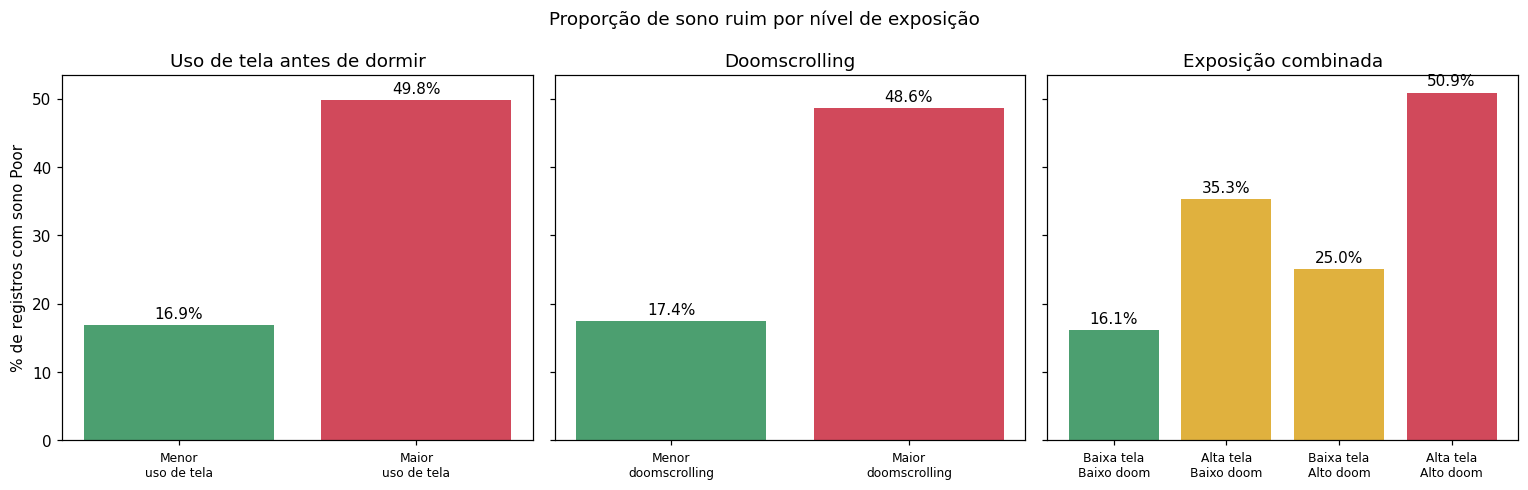

In [20]:
fig, eixos = plt.subplots(1, 3, figsize=(14, 4.5), sharey=True)
conjuntos = [
    (poor_tela.reindex(['Menor uso de tela', 'Maior uso de tela']), 'Uso de tela antes de dormir'),
    (poor_doom.reindex(['Menor doomscrolling', 'Maior doomscrolling']), 'Doomscrolling'),
    (poor_combinado.reindex([
        'Baixa tela + Baixo doom',
        'Alta tela + Baixo doom',
        'Baixa tela + Alto doom',
        'Alta tela + Alto doom',
    ]), 'Exposição combinada'),
]

for ax, (serie, titulo) in zip(eixos, conjuntos):
    cores_barras = (
        ['#4C9F70', '#D1495B'] if len(serie) == 2
        else ['#4C9F70', '#E0B13E', '#E0B13E', '#D1495B']
    )
    ax.bar(range(len(serie)), serie.values, color=cores_barras)
    for i, valor in enumerate(serie.values):
        ax.text(i, valor + 1, f'{valor:.1f}%', ha='center')
    ax.set_xticks(range(len(serie)))
    ax.set_xticklabels([
        texto.replace(' + ', '\n') if len(serie) == 4
        else texto.replace(' ', '\n', 1)
        for texto in serie.index
    ], fontsize=8)
    ax.set_title(titulo)

eixos[0].set_ylabel('% de registros com sono Poor')
plt.suptitle('Proporção de sono ruim por nível de exposição')
plt.tight_layout()
plt.show()

### Como interpretar o Qui-Quadrado?

O teste verifica se a distribuição de `Poor` e `não-Poor` é independente dos grupos de exposição. Um valor de `p` pequeno sugere associação entre as variáveis nesta base.

O teste não demonstra que telas ou doomscrolling causam sono ruim. Além disso, os grupos de exposição foram definidos pela mediana observada no dataset; essa divisão serve para comparar registros, não representa um limite clínico.

## 14. Regressão logística binária e ordinal

In [21]:
import statsmodels.api as sm
from statsmodels.miscmodels.ordinal_model import OrderedModel

# Esta é uma análise de associação separada da avaliação preditiva do SVM.
# Para preservar os registros nesta análise, a cafeína ausente é preenchida
# pela mediana da própria amostra; essa etapa não alimenta o Pipeline do SVM.
df_associacao = df.copy()
mediana_cafeina = df_associacao['caffeine_intake_mg_per_day'].median()
df_associacao['caffeine_intake_mg_per_day'] = (
    df_associacao['caffeine_intake_mg_per_day'].fillna(mediana_cafeina)
)

colunas_regressao = [
    'bedtime_screen_time_minutes',
    'doomscroll_minutes_per_night',
    'age',
    'stress_score',
    'anxiety_score',
    'caffeine_intake_mg_per_day',
]
Xo = df_associacao[colunas_regressao].copy()

# Reescalamos as duas exposições para interpretar o OR por 30 minutos adicionais.
Xo['bedtime_screen_time_minutes'] /= 30
Xo['doomscroll_minutes_per_night'] /= 30
n_variaveis = len(colunas_regressao)

# 1) Regressão logística binária: Poor (1) vs. não-Poor (0).
y_associacao_bin = (df_associacao[COLUNA_ALVO] == 'Poor').astype(int)
X_logit = sm.add_constant(Xo)
resultado_logit = sm.Logit(y_associacao_bin, X_logit).fit(disp=False)

ic_logit = resultado_logit.conf_int().iloc[1:]
tabela_logit = pd.DataFrame({
    'OR': np.exp(resultado_logit.params.iloc[1:]),
    'IC95_inf': np.exp(ic_logit[0]),
    'IC95_sup': np.exp(ic_logit[1]),
    'p': resultado_logit.pvalues.iloc[1:],
}).round(3)

print('Regressão logística — OR > 1 indica maiores odds de sono Poor:')
display(tabela_logit)

# 2) Regressão ordinal: utiliza a ordem Poor < Fair < Good.
df_associacao['qualidade_ordenada'] = pd.Categorical(
    df_associacao[COLUNA_ALVO],
    categories=['Poor', 'Fair', 'Good'],
    ordered=True,
)
resultado_ordinal = OrderedModel(
    df_associacao['qualidade_ordenada'],
    Xo,
    distr='logit',
).fit(method='bfgs', disp=False)

ic_ordinal = resultado_ordinal.conf_int().iloc[:n_variaveis]
tabela_ordinal = pd.DataFrame({
    'OR': np.exp(resultado_ordinal.params.iloc[:n_variaveis]),
    'IC95_inf': np.exp(ic_ordinal[0]),
    'IC95_sup': np.exp(ic_ordinal[1]),
    'p': resultado_ordinal.pvalues.iloc[:n_variaveis],
}).round(3)

print('\nRegressão ordinal — categorias ordenadas Poor < Fair < Good:')
display(tabela_ordinal)

Regressão logística — OR > 1 indica maiores odds de sono Poor:


,OR,IC95_inf,IC95_sup,p
bedtime_screen_time_minutes,1.899,1.261,2.859,0.002
doomscroll_minutes_per_night,1.393,0.992,1.955,0.055
age,0.988,0.969,1.008,0.244
stress_score,0.953,0.864,1.052,0.340
anxiety_score,1.123,1.008,1.252,0.036
caffeine_intake_mg_per_day,1.001,0.999,1.002,0.535



Regressão ordinal — categorias ordenadas Poor < Fair < Good:


,OR,IC95_inf,IC95_sup,p
bedtime_screen_time_minutes,0.539,0.388,0.749,0.000
doomscroll_minutes_per_night,0.709,0.543,0.925,0.011
age,1.006,0.990,1.023,0.449
stress_score,1.041,0.961,1.127,0.328
anxiety_score,0.922,0.844,1.007,0.073
caffeine_intake_mg_per_day,1.000,0.998,1.001,0.767


### Como interpretar o Odds Ratio (OR)?

Na regressão binária, `OR > 1` indica aumento das *odds* de pertencer à classe `Poor`; `OR < 1` indica redução. O intervalo de confiança de 95% mostra uma faixa de valores compatíveis com os dados segundo o modelo. Quando o intervalo inclui 1, não há evidência estatística clara de associação naquele nível de confiança.

O OR de tela e o OR de doomscrolling foram escalados para cada 30 minutos adicionais. Por exemplo, OR = 1,90 significa odds 90% maiores por aumento de 30 minutos, mantidas as demais variáveis constantes — não significa aumento de 90 pontos percentuais na probabilidade.

Na regressão ordinal, as categorias estão ordenadas `Poor < Fair < Good`. A interpretação do OR depende da parametrização do modelo e da ordem escolhida; por isso o texto impresso identifica explicitamente essa ordem.

A imputação da mediana de cafeína nesta seção é restrita à análise de associação. Ela é separada do pipeline preditivo e não é usada para calcular a acurácia do SVM.

## 15. Probabilidades previstas pela regressão

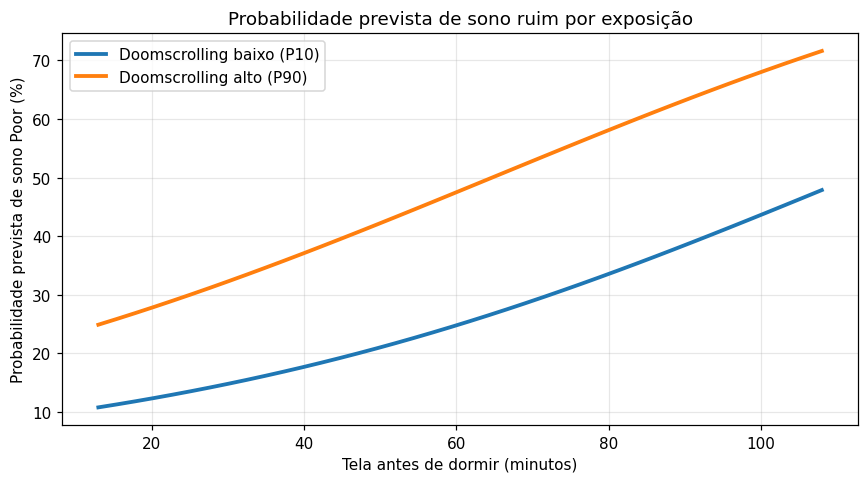

In [22]:
# Curvas de probabilidade de Poor para diferentes níveis de doomscrolling.
tela_minutos = np.linspace(
    df_associacao['bedtime_screen_time_minutes'].quantile(0.05),
    df_associacao['bedtime_screen_time_minutes'].quantile(0.95),
    40,
)

fig, ax = plt.subplots(figsize=(8, 4.5))
for quantil, rotulo in [
    (0.10, 'Doomscrolling baixo (P10)'),
    (0.90, 'Doomscrolling alto (P90)'),
]:
    grade = pd.concat([X_logit.mean().to_frame().T] * len(tela_minutos), ignore_index=True)
    grade['bedtime_screen_time_minutes'] = tela_minutos / 30
    grade['doomscroll_minutes_per_night'] = (
        df_associacao['doomscroll_minutes_per_night'].quantile(quantil) / 30
    )
    ax.plot(
        tela_minutos,
        resultado_logit.predict(grade) * 100,
        label=rotulo,
        linewidth=2.5,
    )

ax.set_xlabel('Tela antes de dormir (minutos)')
ax.set_ylabel('Probabilidade prevista de sono Poor (%)')
ax.set_title('Probabilidade prevista de sono ruim por exposição')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [23]:
# Cenários nos percentis 10, 50 e 90 das duas exposições.
niveis_exposicao = {
    'Exposição baixa (P10)': 0.10,
    'Exposição mediana (P50)': 0.50,
    'Exposição alta (P90)': 0.90,
}

cenarios = pd.concat([Xo.mean().to_frame().T] * 3, ignore_index=True)
cenarios['bedtime_screen_time_minutes'] = [
    df_associacao['bedtime_screen_time_minutes'].quantile(q) / 30
    for q in niveis_exposicao.values()
]
cenarios['doomscroll_minutes_per_night'] = [
    df_associacao['doomscroll_minutes_per_night'].quantile(q) / 30
    for q in niveis_exposicao.values()
]

probabilidades = pd.DataFrame(
    np.asarray(resultado_ordinal.predict(cenarios)),
    columns=['Poor', 'Fair', 'Good'],
    index=niveis_exposicao.keys(),
) * 100

print('Probabilidade prevista de cada categoria (%):')
display(probabilidades.round(1))

Probabilidade prevista de cada categoria (%):


,Poor,Fair,Good
Exposição baixa (P10),11.7,29.6,58.7
Exposição mediana (P50),27.3,39.3,33.4
Exposição alta (P90),63.9,26.5,9.6


## 16. Comparação das formulações do desfecho

Além da análise principal `Poor` vs. `não-Poor`, comparamos duas formulações complementares: `Good` vs. demais e as três categorias. Cada tarefa é ajustada apenas no treino e avaliada no mesmo teste reservado. As formulações são análises definidas pelo objetivo do estudo; não são usadas para escolher parâmetros olhando o teste.

In [24]:
# Formulação complementar 1: Good vs. não-Good.
gs_good = GridSearchCV(
    estimator=clone(pipe_sel),
    param_grid=grade_sel,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1,
    refit=True,
)
gs_good.fit(X_train, y_train_good)
y_pred_good = gs_good.predict(X_test)
acc_good = accuracy_score(y_test_good, y_pred_good)
auc_good = roc_auc_score(y_test_good, gs_good.decision_function(X_test))
base_good = max(y_test_good.mean(), 1 - y_test_good.mean())

# Formulação complementar 2: classificação em Good, Fair e Poor.
gs_3classes = GridSearchCV(
    estimator=clone(pipe_sel),
    param_grid=grade_sel,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1,
    refit=True,
)
gs_3classes.fit(X_train, y_train)
y_pred_3classes = gs_3classes.predict(X_test)
acc_3classes = accuracy_score(y_test, y_pred_3classes)
base_3classes = y_test.value_counts(normalize=True).max()

pontuacao_3classes = gs_3classes.decision_function(X_test)
classes_3 = list(gs_3classes.classes_)
auc_3classes = np.mean([
    roc_auc_score(y_test == classe, pontuacao_3classes[:, indice])
    for indice, classe in enumerate(classes_3)
])

linhas_formulacoes = [
    {
        'Formulação': 'Poor vs. resto (principal)',
        'CV (treino)': melhor_busca.best_score_,
        'Teste': acuracia_teste,
        'Linha de base': linha_base,
        'AUC': auc_poor,
    },
    {
        'Formulação': 'Good vs. resto',
        'CV (treino)': gs_good.best_score_,
        'Teste': acc_good,
        'Linha de base': base_good,
        'AUC': auc_good,
    },
    {
        'Formulação': '3 classes (Good, Fair, Poor)',
        'CV (treino)': gs_3classes.best_score_,
        'Teste': acc_3classes,
        'Linha de base': base_3classes,
        'AUC': auc_3classes,
    },
]

tabela_formulacoes = pd.DataFrame(linhas_formulacoes).set_index('Formulação')
tabela_formulacoes['Ganho vs. base (p.p.)'] = (
    tabela_formulacoes['Teste'] - tabela_formulacoes['Linha de base']
) * 100
print('Comparação das tarefas de classificação:')
display(tabela_formulacoes.round(3))

Comparação das tarefas de classificação:


,CV (treino),Teste,Linha de base,AUC,Ganho vs. base (p.p.)
Formulação,,,,,
Poor vs. resto (principal),0.819,0.810,0.67,0.869,14.0
Good vs. resto,0.766,0.785,0.66,0.821,12.5
"3 classes (Good, Fair, Poor)",0.607,0.590,0.34,0.751,25.0


### Cuidado ao comparar as formulações

A acurácia de uma tarefa binária não é diretamente comparável à acurácia de uma tarefa de três classes, porque a linha de base muda. Por isso a tabela mostra também a linha de base e o ganho em pontos percentuais. AUC também deve ser interpretada com atenção, pois o problema multiclasses usa uma média one-vs-rest.

## 17. Avaliação ordinal do SVM de três classes

Parâmetros do SVM de três classes: {'selecao__k': 15, 'svm__C': 10, 'svm__class_weight': None, 'svm__gamma': 0.01, 'svm__kernel': 'rbf'}
Acurácia exata: 59.0%
Acurácia a até uma categoria de distância: 94.5%
Kappa ponderado quadrático: 0.593
Erro absoluto médio (categorias): 0.465

Matriz de confusão — linhas = real; colunas = previsto:


,Previsto: Poor,Previsto: Fair,Previsto: Good
Real: Poor,45,14,7
Real: Fair,14,23,29
Real: Good,4,14,50


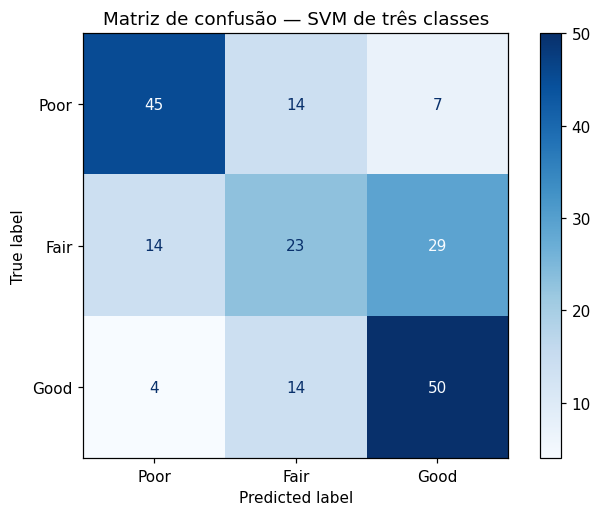

In [25]:
from sklearn.metrics import cohen_kappa_score, mean_absolute_error

# Para medir a distância entre categorias, usamos a ordem Poor < Fair < Good.
ordem_numerica = {'Poor': 0, 'Fair': 1, 'Good': 2}
y_teste_ordinal = y_test.map(ordem_numerica).to_numpy()
y_previsto_ordinal = pd.Series(
    y_pred_3classes, index=y_test.index
).map(ordem_numerica).to_numpy()

acc3 = accuracy_score(y_teste_ordinal, y_previsto_ordinal)
acc_ate_uma_categoria = (
    np.abs(y_teste_ordinal - y_previsto_ordinal) <= 1
).mean()
kappa3 = cohen_kappa_score(
    y_teste_ordinal, y_previsto_ordinal, weights='quadratic'
)
mae3 = mean_absolute_error(y_teste_ordinal, y_previsto_ordinal)

print('Parâmetros do SVM de três classes:', gs_3classes.best_params_)
print(f'Acurácia exata: {acc3 * 100:.1f}%')
print(f'Acurácia a até uma categoria de distância: {acc_ate_uma_categoria * 100:.1f}%')
print(f'Kappa ponderado quadrático: {kappa3:.3f}')
print(f'Erro absoluto médio (categorias): {mae3:.3f}')

# A ordem da matriz acompanha a escala ordinal Poor -> Fair -> Good.
ordem_matriz = ['Poor', 'Fair', 'Good']
matriz_3classes = confusion_matrix(
    y_test,
    y_pred_3classes,
    labels=ordem_matriz,
)
print('\nMatriz de confusão — linhas = real; colunas = previsto:')
display(pd.DataFrame(
    matriz_3classes,
    index=[f'Real: {c}' for c in ordem_matriz],
    columns=[f'Previsto: {c}' for c in ordem_matriz],
))

ConfusionMatrixDisplay(
    confusion_matrix=matriz_3classes,
    display_labels=ordem_matriz,
).plot(cmap='Blues', values_format='d')
plt.title('Matriz de confusão — SVM de três classes')
plt.tight_layout()
plt.show()

### Por que usar métricas ordinais?

A acurácia exata considera qualquer erro como erro: prever `Good` quando o real é `Fair` conta igual a prever `Poor` quando o real é `Good`. Como as categorias têm ordem, também apresentamos:

- **Acurácia a até uma categoria:** conta previsões exatas e previsões que erraram apenas uma posição na escala.
- **Kappa ponderado quadrático:** considera a distância entre as categorias ao comparar previsão e valor real.
- **Erro absoluto médio:** mede a distância média entre classe prevista e classe real na escala ordinal.

A matriz foi ordenada como `Poor`, `Fair`, `Good` para corresponder à codificação usada nessas métricas.

## 18. Resumo e conclusão automática

In [26]:
def formato_numero(valor, casas=1):
    return f'{valor:.{casas}f}'.replace('.', ',')

def formato_percentual(valor, casas=1):
    return formato_numero(valor * 100, casas)

linha_tela = tabela_logit.loc['bedtime_screen_time_minutes']
linha_doom = tabela_logit.loc['doomscroll_minutes_per_night']
linha_ord_tela = tabela_ordinal.loc['bedtime_screen_time_minutes']
linha_ord_doom = tabela_ordinal.loc['doomscroll_minutes_per_night']

resumo = f'''### Resultado da execução revisada

Foram analisados **{len(df)} registros** do dataset. A divisão foi de **{len(X_train)} registros para treino** e **{len(X_test)} para teste**, com estratificação pelas três categorias. A imputação, o One-Hot Encoding, a padronização e a seleção de variáveis foram realizados dentro do pipeline, ajustados somente com os dados de treinamento de cada fold.

Para a tarefa principal (**Poor vs. não-Poor**), o modelo selecionado foi **{nome_final}**, com acurácia média de **{formato_percentual(melhor_busca.best_score_)}%** na validação cruzada e **{formato_percentual(acuracia_teste)}%** no teste. A linha de base no teste foi **{formato_percentual(linha_base, 0)}%**. A acurácia balanceada foi **{formato_percentual(acc_bal)}%**, o AUC foi **{formato_numero(auc_poor, 3)}**, a precisão de Poor foi **{formato_percentual(prec_poor)}%** e o recall de Poor foi **{formato_percentual(rec_poor)}%**.

Na tarefa de três classes, a acurácia exata foi **{formato_percentual(acc3)}%**, a acurácia a até uma categoria foi **{formato_percentual(acc_ate_uma_categoria)}%**, o kappa ponderado quadrático foi **{formato_numero(kappa3, 3)}** e o erro absoluto médio foi **{formato_numero(mae3, 3)}**.

Na regressão logística, cada 30 minutos adicionais de tela antes de dormir apresentou OR = **{formato_numero(linha_tela['OR'], 2)}** (IC 95%: {formato_numero(linha_tela['IC95_inf'], 2)} a {formato_numero(linha_tela['IC95_sup'], 2)}). Para o doomscrolling, o OR foi **{formato_numero(linha_doom['OR'], 2)}** (IC 95%: {formato_numero(linha_doom['IC95_inf'], 2)} a {formato_numero(linha_doom['IC95_sup'], 2)}). Na regressão ordinal, os OR foram **{formato_numero(linha_ord_tela['OR'], 2)}** para tela e **{formato_numero(linha_ord_doom['OR'], 2)}** para doomscrolling.

**Conclusão:** os resultados descrevem associações na base analisada e não demonstram causalidade. O desempenho do SVM deve ser interpretado considerando que o conjunto é sintético e que as variáveis de entrada incluem características de sono e bem-estar, além das variáveis de exposição digital.'''

display(Markdown(resumo))

### Resultado da execução revisada

Foram analisados **1000 registros** do dataset. A divisão foi de **800 registros para treino** e **200 para teste**, com estratificação pelas três categorias. A imputação, o One-Hot Encoding, a padronização e a seleção de variáveis foram realizados dentro do pipeline, ajustados somente com os dados de treinamento de cada fold.

Para a tarefa principal (**Poor vs. não-Poor**), o modelo selecionado foi **SVM com seleção de variáveis**, com acurácia média de **81,9%** na validação cruzada e **81,0%** no teste. A linha de base no teste foi **67%**. A acurácia balanceada foi **76,6%**, o AUC foi **0,869**, a precisão de Poor foi **75,0%** e o recall de Poor foi **63,6%**.

Na tarefa de três classes, a acurácia exata foi **59,0%**, a acurácia a até uma categoria foi **94,5%**, o kappa ponderado quadrático foi **0,593** e o erro absoluto médio foi **0,465**.

Na regressão logística, cada 30 minutos adicionais de tela antes de dormir apresentou OR = **1,90** (IC 95%: 1,26 a 2,86). Para o doomscrolling, o OR foi **1,39** (IC 95%: 0,99 a 1,96). Na regressão ordinal, os OR foram **0,54** para tela e **0,71** para doomscrolling.

**Conclusão:** os resultados descrevem associações na base analisada e não demonstram causalidade. O desempenho do SVM deve ser interpretado considerando que o conjunto é sintético e que as variáveis de entrada incluem características de sono e bem-estar, além das variáveis de exposição digital.